# E-Commerce Customer & Sales Intelligence — EDA & Data Cleaning

**Dataset:** Olist Brazilian E-Commerce (2016–2018, ~100k orders)

**Is notebook ka goal (Hinglish):**

1. Raw data ko load aur inspect karna (kya problems hain, yeh dekhna)
2. Har table ko clean karna — har decision ka reasoning ke saath (kya galat tha, kyun matter karta hai, humne kya kiya, kyun wahi method chuna)
3. Cleaned data ko `data/processed/` mein export karna (SQL aur Power BI dono isi cleaned data ko use karenge)
4. Descriptive statistics, univariate analysis, aur important relationships explore karna
5. Business-relevant charts banana — har chart ke saath: why this chart / what it shows / what to notice / business decision it could influence

> Detailed cleaning explanations `docs/02_data_cleaning.md` mein bhi hain (yeh notebook + wo doc dono saath padhna best hai). Full column/table reference `docs/01_dataset_understanding.md` mein hai.

## 1. Setup & Imports

Hum sirf wahi libraries use kar rahe hain jo genuinely zaroori hain:
- `pandas` — data load/clean/aggregate karne ke liye
- `numpy` — numeric operations ke liye
- `matplotlib` / `seaborn` — charts banane ke liye
- `pathlib` — file paths handle karne ke liye (OS-independent way)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project root = parent of the notebooks/ folder this file lives in
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Raw data folder:", RAW_DIR)
print("Processed data folder:", PROCESSED_DIR)

Raw data folder: C:\Users\shiva\Desktop\PLACEMENT PROJECTS\DA\data\raw
Processed data folder: C:\Users\shiva\Desktop\PLACEMENT PROJECTS\DA\data\processed


## 2. Load Raw Data

**Business question jo hum yahan solve kar rahe hain:** "Kya humara data load ho pa raha hai bina
kisi error ke, aur kya wo utna hi hai jitna expect kar rahe the?"

Hum saare 9 raw CSV files ko alag-alag DataFrames mein load karenge. Naming convention: variable
naam table ka short name hoga (e.g. `orders`, `customers`) — isse aage ka code readable rahega.

In [2]:
customers = pd.read_csv(RAW_DIR / "olist_customers_dataset.csv")
geolocation = pd.read_csv(RAW_DIR / "olist_geolocation_dataset.csv")
orders = pd.read_csv(RAW_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(RAW_DIR / "olist_order_items_dataset.csv")
order_payments = pd.read_csv(RAW_DIR / "olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(RAW_DIR / "olist_order_reviews_dataset.csv")
products = pd.read_csv(RAW_DIR / "olist_products_dataset.csv")
sellers = pd.read_csv(RAW_DIR / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(RAW_DIR / "product_category_name_translation.csv")

tables = {
    "customers": customers,
    "geolocation": geolocation,
    "orders": orders,
    "order_items": order_items,
    "order_payments": order_payments,
    "order_reviews": order_reviews,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation,
}

for name, df in tables.items():
    print(f"{name:22s} -> {df.shape[0]:>9,} rows x {df.shape[1]} cols")

customers              ->    99,441 rows x 5 cols
geolocation            -> 1,000,163 rows x 5 cols
orders                 ->    99,441 rows x 8 cols
order_items            ->   112,650 rows x 7 cols
order_payments         ->   103,886 rows x 5 cols
order_reviews          ->    99,224 rows x 7 cols
products               ->    32,951 rows x 9 cols
sellers                ->     3,095 rows x 4 cols
category_translation   ->        71 rows x 2 cols


## 3. Inspect Data

**Why is step zaroori hai:** Cleaning shuru karne se pehle hume pata hona chahiye *kya* clean
karna hai. Isliye hum check karenge:

1. Column data types (`dtype`) — kya date columns text ki tarah stored hain? kya numeric columns
   sahi type mein hain?
2. Missing values (`null` counts) — kaunse columns mein kitna data missing hai?
3. Duplicate rows — kya koi table mein exact duplicate rows hain?

Yeh sab exactly wahi checks hain jo humne `docs/01_dataset_understanding.md` likhne se pehle
`scripts/explore_raw_data.py` mein kiye the — yahan notebook mein hum unhe dobara dikha rahe hain
taaki notebook khud-se-complete (self-contained) rahe.

In [3]:
# dtypes for every table — look for date columns stored as text ("object") instead of datetime
for name, df in tables.items():
    print(f"--- {name} ---")
    print(df.dtypes)
    print()

--- customers ---
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

--- geolocation ---
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

--- orders ---
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

--- order_items ---
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freigh

In [4]:
# null % for every table (only columns that actually have nulls)
for name, df in tables.items():
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    if len(nulls) == 0:
        continue
    print(f"--- {name} ---")
    for col, cnt in nulls.items():
        print(f"  {col}: {cnt:,} ({cnt / len(df) * 100:.2f}%)")
    print()

--- orders ---
  order_approved_at: 160 (0.16%)
  order_delivered_carrier_date: 1,783 (1.79%)
  order_delivered_customer_date: 2,965 (2.98%)

--- order_reviews ---
  review_comment_title: 87,656 (88.34%)
  review_comment_message: 58,247 (58.70%)

--- products ---
  product_category_name: 610 (1.85%)
  product_name_lenght: 610 (1.85%)
  product_description_lenght: 610 (1.85%)
  product_photos_qty: 610 (1.85%)
  product_weight_g: 2 (0.01%)
  product_length_cm: 2 (0.01%)
  product_height_cm: 2 (0.01%)
  product_width_cm: 2 (0.01%)



In [5]:
# fully duplicated rows in every table
for name, df in tables.items():
    dup_count = df.duplicated().sum()
    print(f"{name:22s} -> {dup_count:,} fully duplicated rows")

customers              -> 0 fully duplicated rows


geolocation            -> 261,831 fully duplicated rows
orders                 -> 0 fully duplicated rows
order_items            -> 0 fully duplicated rows
order_payments         -> 0 fully duplicated rows


order_reviews          -> 0 fully duplicated rows
products               -> 0 fully duplicated rows
sellers                -> 0 fully duplicated rows
category_translation   -> 0 fully duplicated rows


### Inspection findings (summary)

- **Date columns are stored as text** (`object` dtype) in `orders`, `order_items`, `order_payments`
  (shipping_limit_date) and `order_reviews` — inn sabko `datetime` mein convert karna hoga.
- **`orders`** mein delivery-lifecycle columns mein nulls hain (`order_approved_at`,
  `order_delivered_carrier_date`, `order_delivered_customer_date`) — yeh expected hai kyunki jo
  orders abhi tak deliver nahi hue (canceled/processing/etc.), unke liye yeh dates exist hi nahi
  karti. **Error nahi hai, business reality hai.**
- **`products`** mein `product_category_name` aur uske sath 3 aur columns mein ~1.85% nulls hain
  (same ~610 rows).
- **`order_reviews`** mein free-text fields (`review_comment_title`, `review_comment_message`)
  mein bahut zyada nulls hain (88% aur 59%) — yeh bhi expected hai (optional text feedback).
- **`geolocation`** mein 261,831 fully duplicate rows hain (~26% of the table) — yeh cleaning mein
  drop karenge.
- Baaki koi table mein duplicate rows nahi mile.

Ab hum table-by-table cleaning shuru karte hain.

## 4. Data Cleaning

**General philosophy (bahut important):** Hum **blindly rows delete nahi karenge.** Har decision
ke peeche ek reason hoga, aur hum us reasoning ko yahan likhenge:

- **What was wrong?** — problem kya thi
- **Why does it matter?** — yeh business/analysis ke liye kyun important hai
- **What did we do?** — humne exactly kya action liya
- **Why this method?** — hume yeh method hi kyun sahi laga (alternatives ke against)

(Same structure `docs/02_data_cleaning.md` mein bhi hai — wahan har decision aur detail se
likha hai.)

### 4.1 Clean `orders`

**What was wrong?** Saare date columns (`order_purchase_timestamp`, `order_approved_at`,
`order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`)
text (`object`) ki tarah stored the, `datetime` ki tarah nahi.

**Why does it matter?** Agar yeh columns text rahenge, toh hum date-math (e.g. "delivery mein
kitne din lage") calculate hi nahi kar payenge — subtraction jaisa operation string par kaam
nahi karta.

**What did we do?** `pd.to_datetime()` se convert kiya, with `errors="coerce"` (matlab agar
koi value corrupt/unparseable hui toh wo `NaT` — Not a Time — ban jayegi, crash nahi hoga).

**Why this method?** `errors="coerce"` safe hai kyunki hum already jaante hain kuch dates
missing hain (null) — coerce unhe gracefully `NaT` bana dega bina crash kiye, aur agar koi
unexpected garbage value ho toh wo bhi silently `NaT` ban jayegi (jise hum baad mein null ki
tarah treat kar sakte hain).

In [6]:
date_cols_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols_orders:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

print(orders[date_cols_orders].dtypes)
print()
print("order_status value counts:")
print(orders["order_status"].value_counts())

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

order_status value counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


### 4.2 Clean `customers`

**What was wrong?** Do cheezein:
1. `customer_zip_code_prefix` numeric (`int64`) tha, jisse leading zero wale zip codes
   (e.g. `01310`) apna `0` khoke `1310` ban jaate hain.
2. Sabse important: `customer_id` **order-level unique** hai, `customer_unique_id` **person-level
   unique** hai (dekhein `docs/01_dataset_understanding.md` section 3.1).

**Why does it matter?** Zip code ka leading zero display/lookup ke liye zaroori hai. Aur
`customer_id` vs `customer_unique_id` ka fark samajhna is poore project ki repeat-customer /
RFM analysis ke liye foundational hai — galat column use karne se galat business conclusion
niklega.

**What did we do?** Zip code ko 5-digit zero-padded **string** bana diya. `customer_unique_id`
ko as-is rakha (already correct) — hum bas explicitly note kar rahe hain ki isे hi customer-level
analysis mein use karenge.

**Why this method?** Zero-padding ek simple, standard fix hai postal codes ke liye (postal codes
"numbers" nahi hote, yeh **identifiers** hote hain — isliye string hona hi sahi hai). Koi row
delete nahi karni padi.

In [7]:
customers["customer_zip_code_prefix"] = (
    customers["customer_zip_code_prefix"].astype(str).str.zfill(5)
)

print("Unique customer_id       :", customers["customer_id"].nunique())
print("Unique customer_unique_id:", customers["customer_unique_id"].nunique())
print("=> customer_unique_id will be our 'real person' key for repeat-customer analysis")
customers[["customer_id", "customer_unique_id", "customer_zip_code_prefix"]].head(3)

Unique customer_id       : 99441


Unique customer_unique_id: 96096
=> customer_unique_id will be our 'real person' key for repeat-customer analysis


,customer_id,customer_unique_id,customer_zip_code_prefix
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151


### 4.3 Clean `order_items`

**What was wrong?** `shipping_limit_date` text format mein tha. Humne yeh bhi verify kiya ki
`price` aur `freight_value` mein koi negative ya zero-or-less value toh nahi hai (jo data-entry
error hoti).

**Why does it matter?** Agar price/freight mein negative values hoti, toh revenue calculations
galat ho jaate. Date column ko datetime banana zaroori hai future date-based analysis ke liye.

**What did we do?** Date column convert kiya. Price/freight ko `describe()` se check kiya —
**koi negative ya zero price nahi mili** (min price ₹0.85, freight min ₹0 — free shipping items
ke liye valid hai). Isliye **koi row remove nahi karni padi** — data already clean tha is regard mein.

**Why this method?** "Outlier investigation" ka matlab hamesha data delete karna nahi hota —
pehle *verify* karo ki outlier genuinely error hai ya legitimate high-value transaction. Yahan
max price ₹6,735 ek real premium product ho sakta hai (e.g. furniture/electronics), isliye
usse remove nahi kiya.

In [8]:
order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"], errors="coerce"
)

print(order_items[["price", "freight_value"]].describe())
print()
print("price <= 0 rows   :", (order_items["price"] <= 0).sum())
print("freight_value < 0 :", (order_items["freight_value"] < 0).sum())

               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000

price <= 0 rows   : 0
freight_value < 0 : 0


### 4.4 Clean `order_payments`

**What was wrong?** `payment_type` mein ek `"not_defined"` category hai (sirf 3 rows out of
103,886 — negligible). `payment_installments` mein 2 rows `0` hain, jabki minimum realistically
`1` hona chahiye (0 installments ka koi business meaning nahi hai).

**Why does it matter?** `"not_defined"` category chart mein ek confusing/meaningless bar bana
degi. Yeh itna chhota hai (0.003%) ki isse alag category banana overkill hoga.

**What did we do?** `"not_defined"` ko `"other"` mein bucket kar diya. `payment_installments == 0`
wale 2 rows ko as-is chhod diya (documented as a known negligible anomaly) — kyunki yeh koi
required business question ko affect nahi karta aur sirf 2 rows hain.

**Why this method?** Jab kisi issue ka data par negligible impact ho (yahan <0.01%), toh
usse "fix" karne mein time lagane se better hai use **document** karna aur move on karna —
yeh khud ek important data-cleaning skill hai (har cheez ko over-engineer mat karo).

In [9]:
order_payments["payment_type"] = order_payments["payment_type"].replace(
    "not_defined", "other"
)
print(order_payments["payment_type"].value_counts())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
other              3
Name: count, dtype: int64


### 4.5 Clean `order_reviews`

**What was wrong?** Do cheezein: (1) date columns text format mein thin. (2) 551 orders ke
liye **more than one review row** exist karti hai (99,224 total review rows but sirf 98,673
unique `order_id`) — customer ne kabhi-kabhi dobara review submit kar diya.

**Why does it matter?** Agar hum duplicate review rows ke saath order-level average rating
calculate karenge, toh un 551 orders ka weight galti se do-guna ho jayega — thoda sa skew
aayega satisfaction metrics mein.

**What did we do?** Date columns convert kiye. Duplicate `order_id` wali rows mein se sirf
**latest review** (by `review_answer_timestamp`) rakha, baaki drop kar diye.

**Why this method?** Latest review usually customer ka **final/updated opinion** represent
karta hai (ho sakta hai pehla review kisi issue ke time submit hua ho aur baad mein resolve
hone ke baad customer ne dobara review diya ho). Isse har order ka exactly ek hi review record
milta hai — clean 1:1 relationship jo aage ke joins ke liye zaroori hai.

In [10]:
order_reviews["review_creation_date"] = pd.to_datetime(
    order_reviews["review_creation_date"], errors="coerce"
)
order_reviews["review_answer_timestamp"] = pd.to_datetime(
    order_reviews["review_answer_timestamp"], errors="coerce"
)

before = len(order_reviews)
order_reviews = (
    order_reviews.sort_values("review_answer_timestamp")
    .drop_duplicates(subset="order_id", keep="last")
    .reset_index(drop=True)
)
after = len(order_reviews)

print(f"Rows before: {before:,}  after: {after:,}  removed: {before - after:,}")
print("Unique order_id now equals row count:", order_reviews["order_id"].nunique() == len(order_reviews))

Rows before: 99,224  after: 98,673  removed: 551


Unique order_id now equals row count: True


### 4.6 Clean `products` (+ category translation)

**What was wrong?** 610 products (1.85%) missing `product_category_name` (aur uske saath
name-length/description-length/photo-qty bhi missing). Category translation file mein 71
categories hain lekin products mein 73 raw category names hain — 2 categories ka translation
hi nahi mila, jisse total 623 products bina English category label ke reh jaate. Alag se,
sirf **2 rows** mein `product_weight_g`/dimensions missing hain.

**Why does it matter?** Product/category performance analysis (business question set #3) ke
liye har product ka ek valid category label hona chahiye, warna wo products silently analysis
se chhoot jayenge ya `NaN` ki wajah se error dega.

**What did we do?**
1. Missing `product_category_name` ko `"unknown"` string se fill kiya (delete nahi kiya —
   price/dimension data abhi bhi valid/useful hai).
2. `category_translation` table se left-join kiya; jahan translation nahi mila (missing ya
   `"unknown"`), wahan bhi `"unknown"` category assign kiya — taaki koi bhi product bina
   category label ke na reh jaaye.
3. Sirf 2 rows jinke weight/dimensions missing the, unhe **drop** kiya — itna chhota count hai
   (0.006%) ki physical dimensions ko fabricate karne se better hai unhe exclude karna.

**Why this method?** "Unknown" ek honest label hai — hum fake category naam nahi bana rahe,
sirf transparently keh rahe hain "iski category pata nahi hai." Yeh best practice hai jab
kisi categorical column mein missing values ho aur delete karna information waste karega.

In [11]:
# 1) fill missing category with "unknown"
products["product_category_name"] = products["product_category_name"].fillna("unknown")

# 2) merge English translation, fall back to "unknown" if no match
products = products.merge(category_translation, on="product_category_name", how="left")
products["product_category_name_english"] = products["product_category_name_english"].fillna(
    "unknown"
)

# 3) drop the 2 rows with missing physical dimensions (negligible, cannot be fabricated)
before = len(products)
products = products.dropna(subset=["product_weight_g", "product_length_cm",
                                    "product_height_cm", "product_width_cm"])
after = len(products)

print(f"Rows dropped (missing dimensions): {before - after}")
print("Remaining nulls in products:")
print(products.isnull().sum()[products.isnull().sum() > 0])
print()
print("Top 10 categories by product count:")
print(products["product_category_name_english"].value_counts().head(10))

Rows dropped (missing dimensions): 2
Remaining nulls in products:
product_name_lenght           609
product_description_lenght    609
product_photos_qty            609
dtype: int64

Top 10 categories by product count:
product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64


### 4.7 Clean `sellers` and `geolocation`

**What was wrong?** `sellers` mein zip code same leading-zero issue tha jo customers mein tha.
`geolocation` mein 261,831 fully duplicate rows the (~26%), aur is table ka grain ek zip code
ke multiple lat/lng "sample points" hai — matlab ek zip prefix ke liye kayi rows ho sakti hain.

**Why does it matter?** Duplicate rows kisi bhi aggregation ko unnecessarily inflate karte hain.
Aur agar hum `geolocation` ko directly `customers`/`sellers` se join karenge without aggregating,
toh ek customer/seller ke liye multiple duplicate rows ban jayengi (fan-out join problem) — jo
revenue jaisi metrics ko galat tarike se multiply kar dega.

**What did we do?** Zip code zero-padded. `geolocation` mein exact duplicate rows drop kiye,
phir **har zip code prefix ke liye ek hi representative row** banayi (mean latitude/longitude,
aur sabse common city/state) — taaki ek zip = ek row ho jaaye, safe join ke liye.

**Why this method?** Mean lat/lng ek zip code area ke andar ke sabhi sample points ka reasonable
"center point" deta hai — map visual ke liye kaafi accurate hai (hume GPS-precision nahi chahiye,
sirf city/region-level visual chahiye).

In [12]:
sellers["seller_zip_code_prefix"] = sellers["seller_zip_code_prefix"].astype(str).str.zfill(5)

geolocation["geolocation_zip_code_prefix"] = (
    geolocation["geolocation_zip_code_prefix"].astype(str).str.zfill(5)
)
geolocation = geolocation.drop_duplicates()

geolocation_agg = (
    geolocation.groupby("geolocation_zip_code_prefix")
    .agg(
        geolocation_lat=("geolocation_lat", "mean"),
        geolocation_lng=("geolocation_lng", "mean"),
        geolocation_city=("geolocation_city", lambda s: s.mode().iat[0]),
        geolocation_state=("geolocation_state", lambda s: s.mode().iat[0]),
    )
    .reset_index()
)

print("geolocation rows after dedup:", len(geolocation))
print("geolocation rows after 1-row-per-zip aggregation:", len(geolocation_agg))
geolocation_agg.head(3)

geolocation rows after dedup: 738332
geolocation rows after 1-row-per-zip aggregation: 19015


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,01001,-23.550227,-46.634039,sao paulo,SP
1,01002,-23.547657,-46.634991,sao paulo,SP
2,01003,-23.549000,-46.635582,sao paulo,SP


## 5. Final Validation

Cleaning ke baad hum dobara check karte hain ki humne jo claim kiya wo actually hua ya nahi —
"trust but verify."

In [13]:
cleaned_tables = {
    "customers": customers,
    "geolocation": geolocation_agg,
    "orders": orders,
    "order_items": order_items,
    "order_payments": order_payments,
    "order_reviews": order_reviews,
    "products": products,
    "sellers": sellers,
}

print("Remaining nulls per table (should only be the EXPECTED ones we discussed):")
for name, df in cleaned_tables.items():
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    if len(nulls) == 0:
        print(f"{name:15s} -> no nulls")
    else:
        print(f"{name:15s} -> {dict(nulls)}")

print()
print("Date columns are now real datetime?")
print(" orders.order_purchase_timestamp:", orders["order_purchase_timestamp"].dtype)
print(" order_reviews.review_creation_date:", order_reviews["review_creation_date"].dtype)

Remaining nulls per table (should only be the EXPECTED ones we discussed):
customers       -> no nulls
geolocation     -> no nulls
orders          -> {'order_approved_at': np.int64(160), 'order_delivered_carrier_date': np.int64(1783), 'order_delivered_customer_date': np.int64(2965)}
order_items     -> no nulls
order_payments  -> no nulls
order_reviews   -> {'review_comment_title': np.int64(87123), 'review_comment_message': np.int64(57898)}
products        -> {'product_name_lenght': np.int64(609), 'product_description_lenght': np.int64(609), 'product_photos_qty': np.int64(609)}
sellers         -> no nulls

Date columns are now real datetime?
 orders.order_purchase_timestamp: datetime64[ns]
 order_reviews.review_creation_date: datetime64[ns]


## 6. Export Cleaned Data

**Why export separately (`data/processed/`)?** SQL analysis (`sql/` folder) aur Power BI dono
ko ek **stable, cleaned** version of the data chahiye. Agar wo log raw data use karte
(text-dates, duplicate geolocation rows, missing categories) toh unhe wahi cleaning dobara
karni padti. Isliye ek hi jagah (yeh notebook) cleaning karke, output ko sabke liye reusable
bana diya.

In [14]:
customers.to_csv(PROCESSED_DIR / "customers.csv", index=False)
geolocation_agg.to_csv(PROCESSED_DIR / "geolocation.csv", index=False)
orders.to_csv(PROCESSED_DIR / "orders.csv", index=False)
order_items.to_csv(PROCESSED_DIR / "order_items.csv", index=False)
order_payments.to_csv(PROCESSED_DIR / "order_payments.csv", index=False)
order_reviews.to_csv(PROCESSED_DIR / "order_reviews.csv", index=False)
products.to_csv(PROCESSED_DIR / "products.csv", index=False)
sellers.to_csv(PROCESSED_DIR / "sellers.csv", index=False)

print("Cleaned CSVs exported to:", PROCESSED_DIR)
for f in sorted(PROCESSED_DIR.glob("*.csv")):
    print(" -", f.name)

Cleaned CSVs exported to: C:\Users\shiva\Desktop\PLACEMENT PROJECTS\DA\data\processed
 - customer_segments.csv
 - customers.csv
 - geolocation.csv
 - order_items.csv
 - order_payments.csv
 - order_reviews.csv
 - orders.csv
 - products.csv
 - sellers.csv


---

**Data cleaning complete.** `data/processed/` ab SQL analysis (`sql/` folder) aur Power BI
dashboard, dono ke liye ready hai.

The notebook continues below with **Exploratory Data Analysis (EDA)** — descriptive statistics,
univariate analysis, relationships between variables, and business-relevant charts.

## 7. Descriptive Statistics

**Kyun zaroori hai:** Charts banane se pehle, key numeric columns ka basic summary
(mean/median/min/max/spread) dekhna chahiye — isse pata chalta hai data kaisा distribute hai
aur kaunse charts sabse useful honge.

In [15]:
# Delivery time in days - a derived column we'll reuse in multiple charts below
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print("Price & freight (order_items):")
print(order_items[["price", "freight_value"]].describe())
print()
print("Review score (order_reviews):")
print(order_reviews["review_score"].describe())
print()
print("Delivery days (orders, delivered only):")
print(orders.loc[orders["order_status"] == "delivered", "delivery_days"].describe())

Price & freight (order_items):
               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000

Review score (order_reviews):
count    98673.000000
mean         4.086386
std          1.347618
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64

Delivery days (orders, delivered only):
count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64


## 8. Univariate Analysis (ek-ek variable ko individually samajhna)

### Chart 1 — Order Status Distribution

- **Why this chart?** Bar chart categorical data (order_status) ke counts dikhane ke liye
  best hai.
- **What does it show?** Har order status (`delivered`, `shipped`, `canceled`, etc.) ke kitne
  orders hain.
- **What to notice?** `delivered` bahut dominant hoga (~97%) — baaki sab statuses chhote
  slices hain.
- **Business decision it could influence:** Confirm karta hai ki humara "delivered-only" filter
  (revenue/delivery/satisfaction ke liye) data ka bahut bada chunk hi cover karta hai, chhota
  sa exclude hota hai — filter safe/reasonable hai.

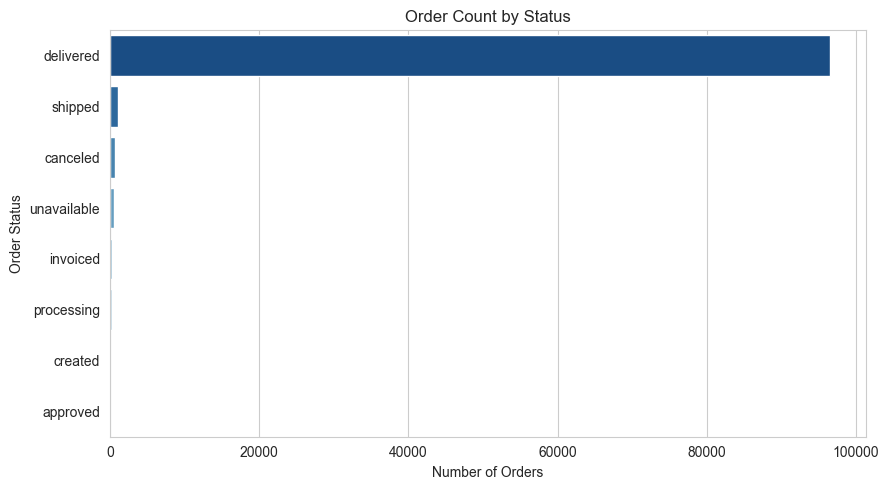

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [16]:
status_counts = orders["order_status"].value_counts()

plt.figure()
sns.barplot(x=status_counts.values, y=status_counts.index, hue=status_counts.index,
            palette="Blues_r", legend=False)
plt.title("Order Count by Status")
plt.xlabel("Number of Orders")
plt.ylabel("Order Status")
plt.tight_layout()
plt.show()

print(status_counts)

### Chart 2 — Review Score Distribution

- **Why this chart?** Customer satisfaction ka core metric hai `review_score` (1-5) — bar
  chart har rating value ka count dikhata hai.
- **What does it show?** Kitne reviews 1★, 2★, 3★, 4★, 5★ hain.
- **What to notice?** Distribution **bimodal** hai — 5★ sabse zyada (majority khush customers),
  lekin 1★ bhi 2★/3★ se zyada hai (matlab jo unhappy hote hain, wo bahut unhappy hote hain,
  beech ka rating kam log dete hain).
- **Business decision it could influence:** Sirf "average rating" dekhna kaafi nahi — 1★ ka
  bada chunk ek red flag hai jo average ke andar "chhup" jaata hai. Root-cause investigation
  (jaise delivery delay — dekho Chart 9) zaroori hai.

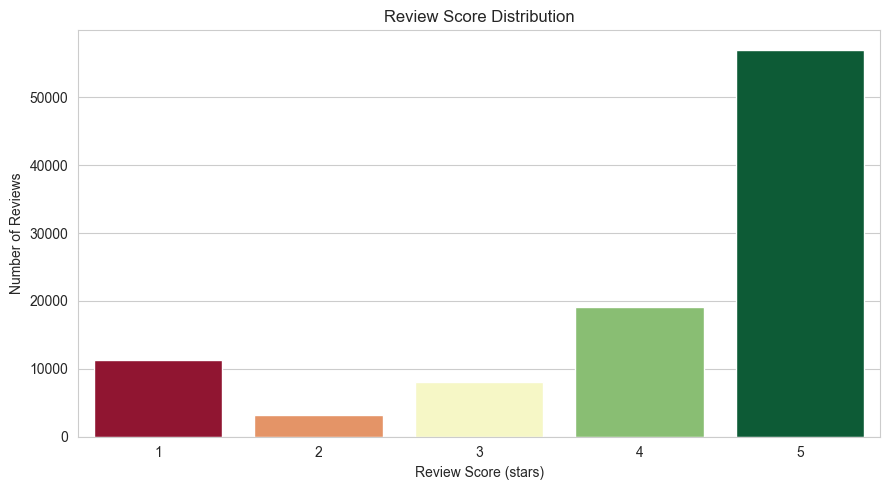

review_score
1    11363
2     3131
3     8133
4    19038
5    57008
Name: count, dtype: int64

Average review score: 4.09


In [17]:
plt.figure()
review_counts = order_reviews["review_score"].value_counts().sort_index()
sns.barplot(x=review_counts.index, y=review_counts.values, hue=review_counts.index,
            palette="RdYlGn", legend=False)
plt.title("Review Score Distribution")
plt.xlabel("Review Score (stars)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

print(review_counts)
print(f"\nAverage review score: {order_reviews['review_score'].mean():.2f}")

### Chart 3 — Price Distribution (log scale)

- **Why this chart?** Histogram continuous numeric data (`price`) ki shape dikhane ke liye
  best hai. **Log scale** isliye use kiya kyunki price data heavily **right-skewed** hai (bahut
  saare cheap products, thode se bahut expensive) — normal scale par sab kuch ek corner mein
  chipak jaata.
- **What does it show?** Product prices ka overall spread.
- **What to notice?** Zyada products low-to-mid price range mein hain; ek lambi "tail" hai
  expensive products ki taraf (jaise `computers` category ka R$1,098 avg price, dekho
  `docs/03_sql_learning.md` Query 3.4).
- **Business decision it could influence:** Pricing/inventory strategy — bulk of the catalog
  budget-friendly hai, premium items niche hain.

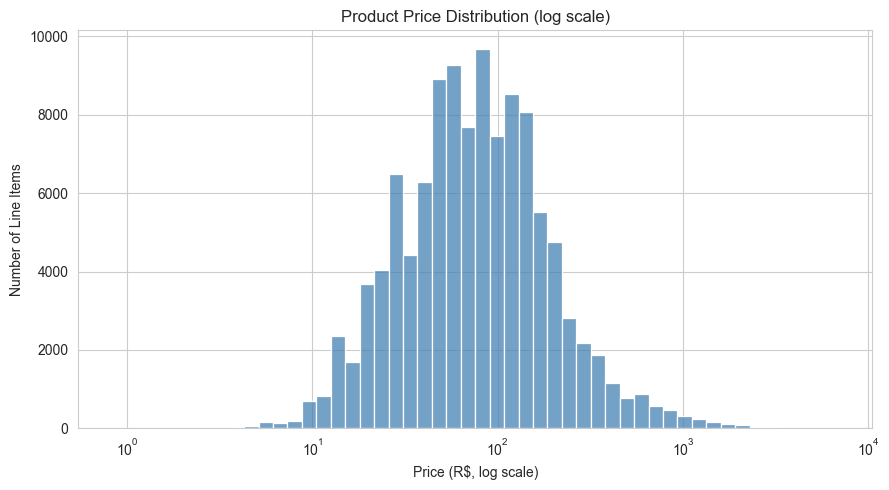

In [18]:
plt.figure()
sns.histplot(order_items["price"], bins=50, log_scale=True, color="steelblue")
plt.title("Product Price Distribution (log scale)")
plt.xlabel("Price (R$, log scale)")
plt.ylabel("Number of Line Items")
plt.tight_layout()
plt.show()

### Chart 4 — Delivery Time Distribution

- **Why this chart?** Histogram — `delivery_days` continuous hai, shape/spread dekhna hai.
- **What does it show?** Order place karne se customer tak pahunchne mein kitne din lagte hain
  (delivered orders only).
- **What to notice?** Average ~12.6 din (dekho Section 7 descriptive stats), lekin ek right
  tail hai (kuch orders 60+ din bhi le lete hain) — yeh tail hi "late delivery" cases hain jo
  satisfaction ko hit karte hain (Chart 9 mein dekhenge).
- **Business decision it could influence:** Operations team ke liye — is tail ko chhota karna
  (outlier-slow deliveries ko fix karna) directly satisfaction improve karega.

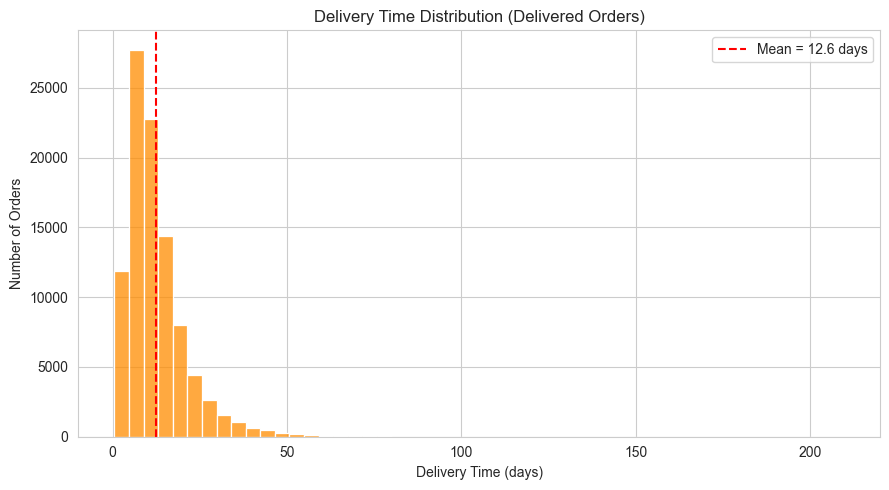

In [19]:
delivered_orders = orders[orders["order_status"] == "delivered"]

plt.figure()
sns.histplot(delivered_orders["delivery_days"].dropna(), bins=50, color="darkorange")
plt.axvline(delivered_orders["delivery_days"].mean(), color="red", linestyle="--",
            label=f"Mean = {delivered_orders['delivery_days'].mean():.1f} days")
plt.title("Delivery Time Distribution (Delivered Orders)")
plt.xlabel("Delivery Time (days)")
plt.ylabel("Number of Orders")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Important Relationships (do ya zyada variables ka connection)

Yahan hum wahi key relationships chart kar rahe hain jo `sql/` folder mein query se nikale the —
SQL "numbers" deta hai, yeh charts unhe **visually samjhne** mein madad karte hain.

### Chart 5 — Monthly Revenue Trend

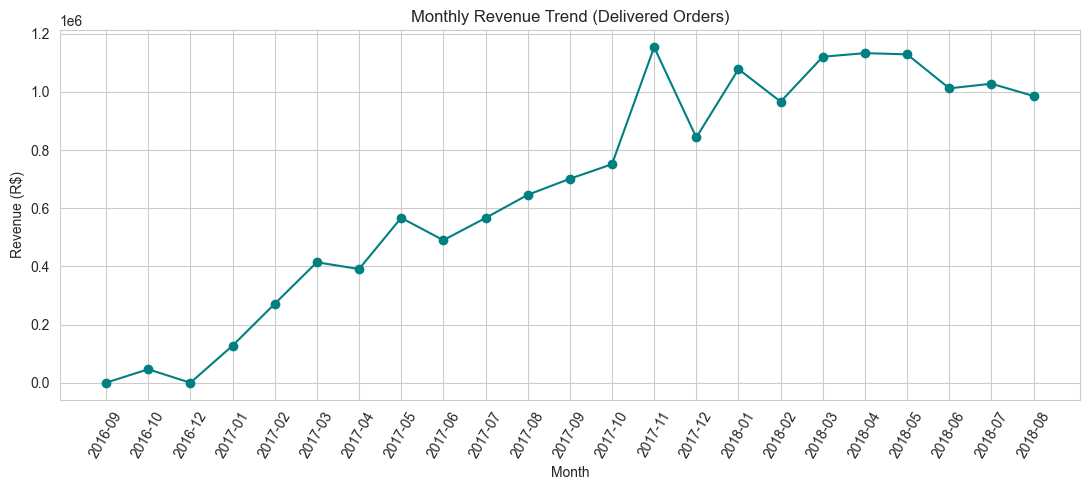

In [20]:
# Build one order-level revenue table we can reuse for several charts below
order_revenue = (
    order_items.merge(orders[["order_id", "order_status", "order_purchase_timestamp",
                               "customer_id"]], on="order_id")
    .query("order_status == 'delivered'")
    .assign(item_revenue=lambda d: d["price"] + d["freight_value"])
    .groupby(["order_id", "order_purchase_timestamp", "customer_id"], as_index=False)
    .agg(order_total=("item_revenue", "sum"))
)

monthly_revenue = (
    order_revenue.assign(order_month=order_revenue["order_purchase_timestamp"].dt.to_period("M").astype(str))
    .groupby("order_month", as_index=False)
    .agg(revenue=("order_total", "sum"), orders_count=("order_id", "nunique"))
)

plt.figure(figsize=(11, 5))
plt.plot(monthly_revenue["order_month"], monthly_revenue["revenue"], marker="o", color="teal")
plt.xticks(rotation=60)
plt.title("Monthly Revenue Trend (Delivered Orders)")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.tight_layout()
plt.show()

- **Why this chart?** Line chart time-series data (revenue over months) ke liye best hai —
  trend/direction turant dikh jaata hai.
- **What does it show?** Har month ka total delivered-order revenue, Sep 2016 se Aug 2018 tak.
- **What to notice?** Steady growth 2016 se 2017 tak, **Nov 2017 mein bada spike** (Black
  Friday season), phir 2018 mein ek stable/mature level. ⚠️ Sep-Oct 2018 chart mein bahut kam
  dikhega — yeh **data-collection cutoff hai, real business decline nahi** (in months ke
  orders ko "delivered" status milne ka time hi nahi mila dataset snapshot lene tak).
- **Business decision it could influence:** Seasonal spikes (Nov) ke liye inventory/staffing
  planning; growth-trend confirm karta hai ki business scale kar raha tha.

### Chart 6 — Top 10 Categories by Revenue

- **Why this chart?** Horizontal bar chart — category names lambe hain, horizontal layout
  padhne mein aasan hota hai, aur ranking (highest to lowest) turant dikhta hai.
- **What does it show?** Revenue by product category, sorted descending.
- **What to notice?** `health_beauty` #1 hai — lekin dekho Chart 7 (order volume) mein
  `bed_bath_table` #1 hai — yeh confirm karta hai ki revenue-leader aur volume-leader alag
  categories ho sakti hain.
- **Business decision it could influence:** Marketing budget/inventory priority in top
  categories par focus kar sakta hai.

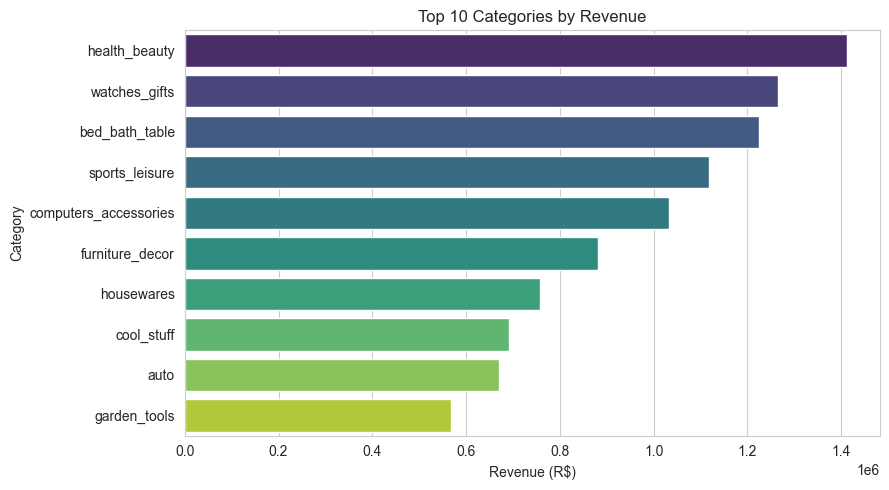

In [21]:
category_revenue = (
    order_items.merge(orders[["order_id", "order_status"]], on="order_id")
    .query("order_status == 'delivered'")
    .merge(products[["product_id", "product_category_name_english"]], on="product_id")
    .assign(item_revenue=lambda d: d["price"] + d["freight_value"])
    .groupby("product_category_name_english", as_index=False)
    .agg(revenue=("item_revenue", "sum"))
    .sort_values("revenue", ascending=False)
    .head(10)
)

plt.figure()
sns.barplot(data=category_revenue, x="revenue", y="product_category_name_english",
            hue="product_category_name_english", palette="viridis", legend=False)
plt.title("Top 10 Categories by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Chart 7 — Top 10 Categories by Order Volume

- **Why this chart?** Same chart type as Chart 6 (horizontal bar), lekin **order count** metric
  — directly comparable side-by-side.
- **What does it show?** Kaunsi categories mein sabse zyada orders aate hain (revenue nahi,
  sirf volume).
- **What to notice?** `bed_bath_table` yahan #1 hai (9,272 orders) but Chart 6 mein revenue
  mein sirf #3 tha — **iska matlab iska per-order value average se kam hai.** Yeh exactly
  "high order volume, relatively lower revenue" pattern hai jo business questions mein poocha
  gaya tha.
- **Business decision it could influence:** `bed_bath_table` jaisi high-volume/lower-value
  category mein average order value badhane ke liye bundling/upsell explore kiya ja sakta hai.

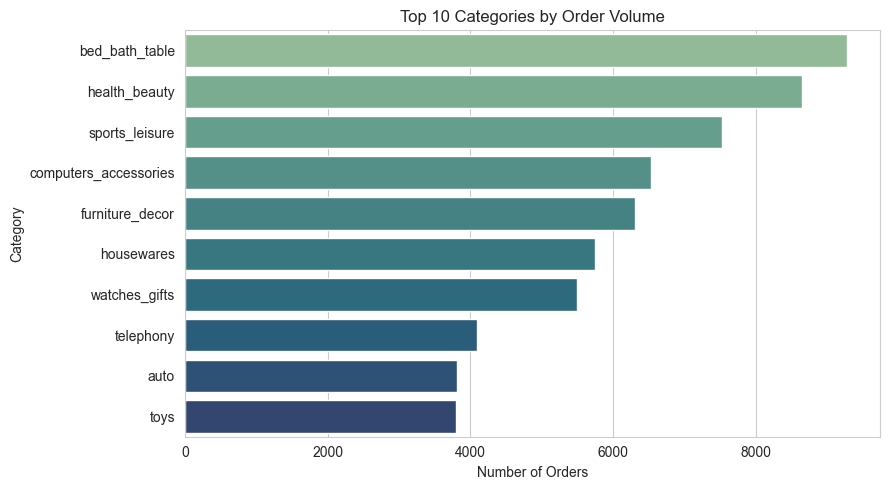

In [22]:
category_orders = (
    order_items.merge(orders[["order_id", "order_status"]], on="order_id")
    .query("order_status == 'delivered'")
    .merge(products[["product_id", "product_category_name_english"]], on="product_id")
    .groupby("product_category_name_english", as_index=False)
    .agg(orders_count=("order_id", "nunique"))
    .sort_values("orders_count", ascending=False)
    .head(10)
)

plt.figure()
sns.barplot(data=category_orders, x="orders_count", y="product_category_name_english",
            hue="product_category_name_english", palette="crest", legend=False)
plt.title("Top 10 Categories by Order Volume")
plt.xlabel("Number of Orders")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Chart 8 — Revenue by State (Top 10)

- **Why this chart?** Bar chart — states ek categorical variable hain, revenue ranking dekhni
  hai.
- **What does it show?** Kaunse Brazilian states sabse zyada revenue contribute karte hain.
- **What to notice?** `SP` (São Paulo) itna dominant hai ki baaki states bahut chhote dikhte
  hain — SP akela ~37% of total revenue hai (dekho `docs/03_sql_learning.md` Query 4.4).
- **Business decision it could influence:** Regional concentration risk — agar SP mein koi
  disruption ho, revenue par bada impact hoga. Geographic expansion/diversification ek
  consideration ho sakta hai.

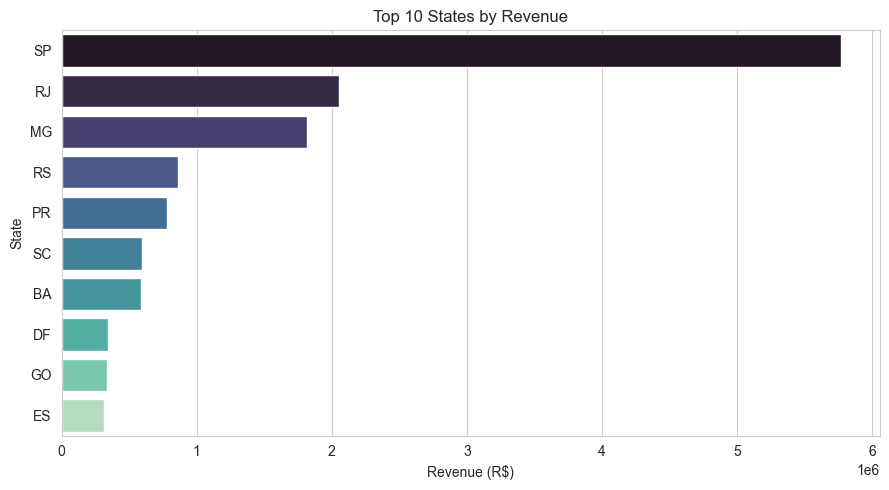

In [23]:
state_revenue = (
    order_revenue.merge(customers[["customer_id", "customer_state"]], on="customer_id")
    .groupby("customer_state", as_index=False)
    .agg(revenue=("order_total", "sum"))
    .sort_values("revenue", ascending=False)
    .head(10)
)

plt.figure()
sns.barplot(data=state_revenue, x="revenue", y="customer_state",
            hue="customer_state", palette="mako", legend=False)
plt.title("Top 10 States by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

### Chart 9 — Delivery Performance vs Customer Satisfaction

- **Why this chart?** Simple 2-bar comparison — do groups (`on_time` vs `late`) ke average
  review score ko side-by-side dikhata hai. Yeh **is poore project ka sabse strong insight**
  hai, isliye ek dedicated chart deserve karta hai.
- **What does it show?** On-time delivered orders vs late delivered orders — dono ka average
  customer rating.
- **What to notice?** Bahut bada gap: on-time ~4.29★ vs late ~2.57★ — matlab delivery delay
  customer satisfaction ko directly, bahut strongly affect karta hai.
- **Business decision it could influence:** Delivery-time improvement ek high-ROI investment
  hai agar goal customer satisfaction/ratings improve karna hai — yeh ek data-backed,
  actionable priority hai operations team ke liye.

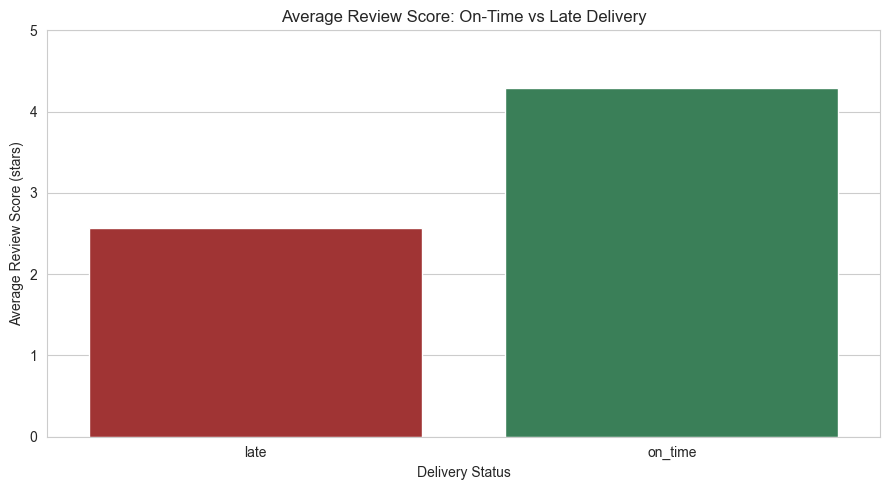

  delivery_status  avg_review_score  orders_count
0            late          2.565070          7661
1         on_time          4.294114         88163


In [24]:
delivery_reviews = (
    delivered_orders[["order_id", "order_delivered_customer_date", "order_estimated_delivery_date"]]
    .dropna()
    .assign(delivery_status=lambda d: (
        d["order_delivered_customer_date"] <= d["order_estimated_delivery_date"]
    ).map({True: "on_time", False: "late"}))
    .merge(order_reviews[["order_id", "review_score"]], on="order_id")
)

summary = delivery_reviews.groupby("delivery_status", as_index=False).agg(
    avg_review_score=("review_score", "mean"), orders_count=("order_id", "nunique")
)

plt.figure()
sns.barplot(data=summary, x="delivery_status", y="avg_review_score",
            hue="delivery_status", palette={"on_time": "seagreen", "late": "firebrick"}, legend=False)
plt.title("Average Review Score: On-Time vs Late Delivery")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score (stars)")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

print(summary)

### Chart 10 — RFM Customer Segment Distribution

- **Why this chart?** Bar chart — segments categorical hain, dono "count" aur "avg revenue"
  ek saath dikhana useful hai (do subplots).
- **What does it show?** RFM segmentation (`sql/06_customer_segmentation.sql`, poora
  explanation `docs/04_customer_segmentation.md` mein) ke 5 segments — kitne customers har
  segment mein hain, aur unka average revenue kya hai.
- **What to notice?** `Recent` sabse bada segment hai (count ke hisab se), lekin `At Risk`
  segment ka **average revenue per customer sabse zyada hai** in-non-high-value segments mein —
  matlab yeh log pehle achha spend karte the.
- **Business decision it could influence:** `At Risk` segment par targeted win-back campaign
  ka ROI sabse zyada hone ki sambhavna hai (proven spenders jo abhi inactive hain).

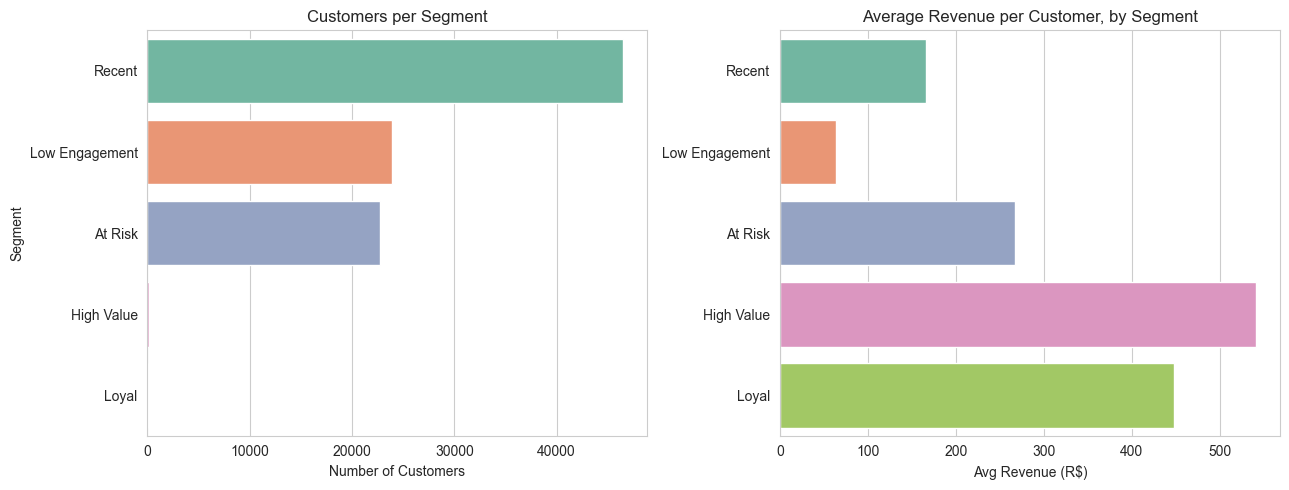

In [25]:
segments = pd.read_csv(PROCESSED_DIR / "customer_segments.csv")
segment_summary = (
    segments.groupby("customer_segment", as_index=False)
    .agg(customers_count=("customer_unique_id", "count"), avg_revenue=("monetary", "mean"))
    .sort_values("customers_count", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=segment_summary, x="customers_count", y="customer_segment",
            hue="customer_segment", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Customers per Segment")
axes[0].set_xlabel("Number of Customers")
axes[0].set_ylabel("Segment")

sns.barplot(data=segment_summary, x="avg_revenue", y="customer_segment",
            hue="customer_segment", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Average Revenue per Customer, by Segment")
axes[1].set_xlabel("Avg Revenue (R$)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 10. Key Observations (EDA summary)

1. **Business is 97% delivery-successful** — only ~3% of orders end up canceled/unavailable/stuck.
2. **Ratings are bimodal** — customers tend to leave either 5★ or 1★ far more than middle ratings;
   averages alone can hide a meaningful unhappy minority.
3. **Product pricing is right-skewed** — most items are budget-to-mid-range, with a long tail of
   premium products (electronics/appliances).
4. **Average delivery time is 12.6 days**, with a long tail of slow outliers pulling the average up.
5. **Revenue grew steadily through 2017**, peaking around November (Black Friday season). The
   apparent Sep–Oct 2018 dip is a data-collection cutoff artifact, not a real decline.
6. **`health_beauty` leads in revenue; `bed_bath_table` leads in order volume** — the two rankings
   diverge, showing category-level average order value varies meaningfully.
7. **Revenue is geographically concentrated** — São Paulo (SP) alone contributes ~37% of total
   revenue.
8. **Delivery performance strongly relates to satisfaction** — on-time orders average 4.29★ vs
   2.57★ for late orders, the single strongest, most actionable relationship found in this project.
9. **RFM segmentation reveals a clear "win-back" opportunity** — the "At Risk" segment has the
   2nd-highest average revenue per customer among all segments, despite being inactive recently.

These observations directly feed into `docs/07_business_insights.md` (Observation → Evidence →
Interpretation → Action format) and the Power BI dashboard design (`docs/06_powerbi_learning.md`).